In [1]:
import sys
import os
import pickle
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt


sys.path.append(os.path.join(os.getcwd(), '../'))
from utils_mouse import read_utils

sys.path.append(os.path.join(os.getcwd(), '../../../../'))
from utils import plot_utils
from utils import train_utils

In [2]:
import importlib
importlib.reload(read_utils)
importlib.reload(plot_utils)
importlib.reload(train_utils)

<module 'utils.train_utils' from '/home/julian-zim/Files/Cloud/OneDrive/OneFiles/Linux/ZimmerLab/MSc_Thesis/Workspace/hobe/utils/train_utils.py'>

In [3]:
# read_ids = list(range(0, 8+1))
read_ids = [2]
plot_id = 2

In [4]:
# read
path = os.path.join(read_utils.get_data_path(), '6163622/sessions')
(file_ids, filenames,
 traces,
 continuous_behaviors,
 motion_pcs,
 motion_masks) = read_utils.get_datas(path, read_ids,
									  with_whisking=True)

# # clear nan values
for i in range(len(file_ids)):
	# mask = motion_pcs[i][0].notna().all(axis=1)
	mask = continuous_behaviors[i].notna().all(axis=1)

	traces[i] = traces[i][mask]
	motion_pcs[i][0] = motion_pcs[i][0][mask]
	motion_pcs[i][1] = motion_pcs[i][1][mask]
	continuous_behaviors[i] = continuous_behaviors[i][mask]

# naive ID unknown neurons
for i in range(len(file_ids)):
	traces[i].columns = pd.Index([
		f'{file_ids[i]:02d}_{n_id:03d}' if empty or type(label) is not str else label for n_id, (label, empty) in enumerate(zip(traces[i].columns, traces[i].columns == ''))
	])

In [5]:
plot_idx = file_ids.index(plot_id)

# states = [ds[selection_bhl] for ds in states]

In [6]:
print(traces[plot_idx].shape)

(10105, 9392)


0.0


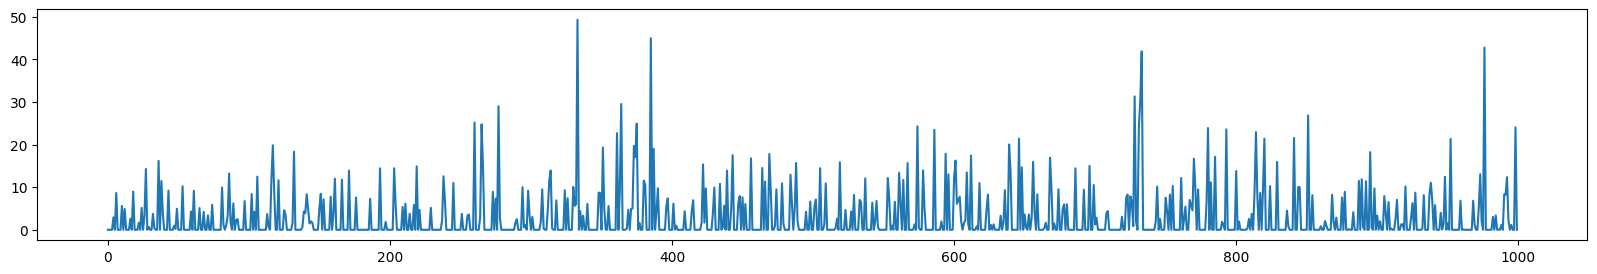

In [7]:
plt.figure(figsize=(20, 3))
plt.plot(traces[plot_idx].values[:1000, 0])

print(np.median(traces[plot_idx]))

In [8]:
def reconstruct_calcium(spikes, fs, tau=2.0):
    """
    Reconstruct calcium trace by exponential integration of spike trains.

    This function always assumes the input `spks` is time-major with shape
    (T, n_neurons) where the first axis is time (T) and the second axis is neurons (N).
    The returned calcium trace has the same orientation: (T, n_neurons).

    Arguments:
      spks: array-like of spikes (counts or floats), shape (T, N)
      fs: sampling rate (Hz)
      tau: decay time constant (same time units as 1/fs)
    """

    dt = 1.0 / fs
    gamma = np.exp(-dt / tau)

    trace = np.zeros(spikes.shape, dtype=float)

    # integrate forward in time: trace[t] = gamma*trace[t-1] + spikes[t]
    for t in range(1, spikes.shape[0]):
        trace[t, :] = gamma * trace[t-1, :] + spikes[t, :]

    return trace

In [9]:
fs = 3.0   # example for multiplane recording
c = reconstruct_calcium(traces[plot_idx].values, fs)

81.9728433460409


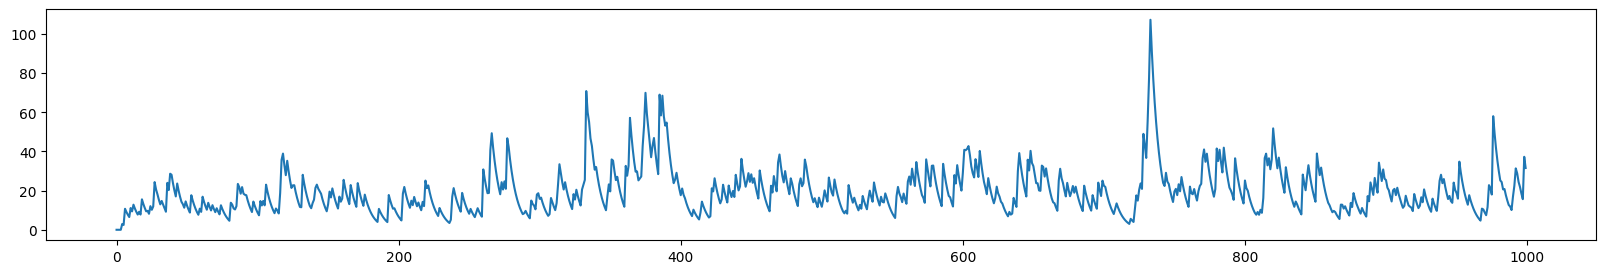

In [10]:
plt.figure(figsize=(20, 3))
plt.plot(c[:1000, 0])

print(np.median(c))